# 00 · Textract Samples

**Goal:** run Amazon Textract on the sample time sheets and loose-note photos, save its full answer, and see what it reads before writing the converters.

Textract takes a picture of a page and returns everything it read: every line and word, where each one sits on the page, and how sure it is (0 to 100). It has two modes:

| Mode | Textract call | Returns | Used for |
|---|---|---|---|
| `sheet` | `AnalyzeDocument` with tables and forms | words, table cells, and labeled fields like `Timekeeper: R. Patel` | time sheets and anything else with columns |
| `note` | `DetectDocumentText` | lines of text | loose notes: sticky notes, napkins, notepads |

The full answer is saved as JSON, one file per page. An earlier table-only export (`ocr/Amazon_textract_output.csv`) kept just the table, so the sheet header, the margin notes, and the confidence scores were lost. The saved JSON keeps all of it, and every later notebook reads the JSON instead of calling Textract again.

**Questions**
1. Does the sheet header (timekeeper, week) come through as labeled fields?
2. Are the margin dates and margin notes read, and where do they land?
3. How sure is Textract about the hours, where a missing decimal point changes the bill?
4. How well does it read loose notes?

## 1. Setup

In [1]:
import io
import sys
from pathlib import Path

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image, ImageOps

sys.path.insert(0, "../src")
from intake import find_timekeeper, timekeeper_table
from textract import (load_pages, outside_table, page_cells, page_fields, page_images, page_lines, run_textract,
                      table_grid)

In [2]:
SHEETS_PATH = Path("../data/sheets/2399_001.pdf")   # 4 handwritten time sheets (HW-01 to HW-04)
NOTES_DIR = Path("../data/notes")              # phone photos of loose notes (JPEG or PNG)
TEXTRACT_DIR = Path("../data/textract")        # saved Textract answers, one JSON per page
TIMEKEEPERS_PATH = Path("../data/timekeepers.csv")
COLUMN_NOTES = ["mon_fri_sample.jpg", "note_07.JPG"]   # notes with drawn columns, also read as a sheet to compare

REGION = "us-west-2"
DPI = 200        # PDF pages are rendered at this resolution before Textract reads them
LOW_CONF = 80    # line confidence (0 to 100) below which text counts as hard to read

In [3]:
NOTES_DIR.mkdir(exist_ok=True)
photos = sorted(p for p in NOTES_DIR.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".heic"})
timekeepers = timekeeper_table(pd.read_csv(TIMEKEEPERS_PATH))

assert SHEETS_PATH.exists()
assert not [p for p in photos if p.suffix.lower() == ".heic"], "Convert HEIC photos to JPEG first"
assert timekeepers["tk_id"].is_unique
print(f"{len(page_images(SHEETS_PATH, DPI))} sheet pages | {len(photos)} note photos | {len(timekeepers)} timekeepers")

4 sheet pages | 9 note photos | 18 timekeepers


## 2. Run Textract

Each page is one Textract call: a few seconds, and charged per page. Answers are saved, so running this cell again skips any page already saved. To read a page again, delete its JSON.

Notes with drawn columns (listed in `COLUMN_NOTES`) are read both ways, as a note and as a sheet, to see which keeps each entry together better.

In [4]:
sheet_files = run_textract(SHEETS_PATH, TEXTRACT_DIR, "sheet", REGION, DPI)
note_files = [f for p in photos for f in run_textract(p, TEXTRACT_DIR, "note", REGION)]
column_files = [f for p in photos if p.name in COLUMN_NOTES for f in run_textract(p, TEXTRACT_DIR, "sheet", REGION)]
print(f"Saved to {TEXTRACT_DIR}: {len(sheet_files)} sheet pages, {len(note_files)} note photos, "
      f"{len(column_files)} column notes read as sheets")

Saved to ../data/textract: 4 sheet pages, 9 note photos, 2 column notes read as sheets


## 3. What came back

In [5]:
sheets = load_pages(TEXTRACT_DIR, SHEETS_PATH, "sheet")
lines = {n: page_lines(p) for n, p in enumerate(sheets, 1)}
cells = {n: page_cells(p) for n, p in enumerate(sheets, 1)}
fields = {n: page_fields(p) for n, p in enumerate(sheets, 1)}

pd.DataFrame([{
    "page": n,
    "lines": len(lines[n]),
    "tables": cells[n]["table"].nunique(),
    "columns": cells[n]["col"].max(),
    "fields": len(fields[n]),
    "handwritten_share": lines[n]["handwritten"].mean(),
    "median_conf": lines[n]["conf"].median(),
} for n in lines]).round(2)

,page,lines,tables,columns,fields,handwritten_share,median_conf
0,1,30,1,3,4,0.83,97.38
1,2,29,1,4,5,0.83,96.47
2,3,26,1,3,4,0.81,93.11
3,4,35,1,3,4,0.83,81.62


- All four sheets came back with one table, the printed header, and 26 to 35 lines of text each.
- About 80% of the text is handwritten. The form's printed labels read near 100, and handwriting reads lower.
- HW-04 (page 4) reads worst, with a median line confidence of 82, against 93 to 97 on the other sheets.

## 4. Sheet header

The form prints `Sheet ID`, `Timekeeper`, and `Week of` at the top. With forms turned on, Textract should return them as labeled fields. The timekeeper name is then looked up in the firm's timekeeper list.

In [6]:
all_fields = pd.concat([f.assign(page=n) for n, f in fields.items()], ignore_index=True)
all_fields[["page", "key", "value", "conf"]].round(1)

,page,key,value,conf
0,1,Sheet ID,HW-02,99.3
1,1,Timekeeper,R. Patel,99.4
2,1,Week of,08/10,98.8
3,1,Description of Work,Tel conference w/ CEO ve hiring questions,82.2
4,2,Sheet ID,HW-03,99.0
5,2,Timekeeper,E. Brandt,98.9
6,2,Week of,09/14,94.1
7,2,Hours,2.4,99.7
8,2,Northwind Ii,cense,25.0
9,3,Sheet ID,HW-01,99.1


In [7]:
names = all_fields[all_fields["key"].str.contains("timekeeper", case=False)].groupby("page")["value"].first()
names.to_frame("timekeeper").assign(tk_id=names.map(lambda n: find_timekeeper(n, timekeepers)))

,timekeeper,tk_id
page,,
1,R. Patel,TK102
2,E. Brandt,TK109
3,L. Moreno,TK103
4,A. Chen,TK101


- Sheet ID, Timekeeper, and Week of came through as labeled fields on all four sheets at 94 to 99 confidence, and every timekeeper maps to the right TK ID.
- Forms mode also finds a few false fields inside the table ("Hours: 2.4", "Northwind Ii: cense"), so the converter should read only the three header fields, by name.

## 5. The table

Each page's table as Textract laid it out. The form has three columns (Hours, Client, Description of Work), so an extra column usually means margin dates were pulled into the table.

In [8]:
for n, c in cells.items():
    print(f"Page {n}: {c['table'].nunique()} table(s), {c['col'].max()} columns")
    display(table_grid(c))

Page 1: 1 table(s), 3 columns


col,1,2,3
row,,,
1,Hours,Client,Description of Work
2,0.4,Halwren Ind.,Tel conference w/ CEO ve hiring
3,,,questions
4,,,
5,1.4,,Advise ne option grant nechanics
6,1.3,5520.001,lattend to matter.
7,3,Halvorson Industrial - -Acq of Brightline,TCW under counsel re acquisition for Brightline;
8,,3012.004,financing prepare sig pckts for Lark closing
9,,,


Page 2: 1 table(s), 4 columns


col,1,2,3,4
row,,,,
1,,Hours,Client,Description of Work
2,09/14,2.4,,Draft side letter for LP(Fund 111);
3,,,,conference re MFN elections.
4,09/17,0.8,1-larorlight Bio,Athend to financing matters.
5,09/18,0.8,4590-003,Attend to finacning mathers.
6,09/18,0.9,Tolewater AI,Reconcile cap tale to Stock ledger
7,09/18,2.9,4590.003,Prepare charter amendment for
8,,,,Project Kite; revise temtory
9,,,,& exclusivity provisions in


Page 3: 1 table(s), 3 columns


col,1,2,3
row,,,
1,Hours,Client,Description of Work
2,1.3,Cobil t Ridge,"nev. 3e, confi dential information memorandum ..."
3,2.3,Ridge Water,review Fund II capital call notice
4,0.9,Daily Journal,respond to buyer DD request
5,0.9,Stand AI,truck Fund III investor Signature subsript
6,1.0,Litera,Respond to LP Maning re Fund I distributions
7,,,draft side letter forlp (Calpine Pension)
8,,,conference ne MFN elections
9,,,


Page 4: 1 table(s), 3 columns


col,1,2,3
row,,,
1,Hours,Client,Description of Work
2,3,Rat Bio -Series B,TCW M. white re new tax plan
3,4.7,Brave Capital-en,TOW A stone re amendments to LPA; make edits t...
4,,,to LPS.
5,2,Firm-admin,attend to genadmin
6,6,Firm-interview,Interview fund / lateral candidate.
7,4,Theories Fund 007,Attend to transfers of GP interest for Wang.
8,9 9,Labs - - Formation,Aeview agreement attend to closing matters
9,2,River Ventures,TCW J. Obberan.


- Each table follows the form's rows, so one line on the sheet is one table row.
- Page 2 (HW-03) has a fourth column: the margin dates were pulled into the table with a blank header. The other pages leave them outside the table.
- Continuation lines ("questions", "to LPs.") come back as rows with no hours, and on page 1 "financing" slid into the row below. These need to be merged into the entry above.
- The drawn arrow on page 1 (row 5, 1.4 hours) comes back as a blank client, so the client has to be copied down from the entry above.

## 6. Text outside the table

Margin dates ("08/11") and margin notes (a CMID written sideways) sit outside the table's box. These are the lines the table-only output lost.

In [9]:
outside = pd.concat([outside_table(lines[n], cells[n]).assign(page=n) for n in lines], ignore_index=True)
outside[["page", "text", "conf", "handwritten", "left", "top"]].round(3)

,page,text,conf,handwritten,left,top
0,1,Sheet ID: HW-02,99.297,False,0.059,0.040
1,1,Timekeeper: R. Patel,99.442,False,0.337,0.041
2,1,Week of: 08/10,98.807,True,0.715,0.027
3,1,08/10,99.753,True,0.010,0.106
4,1,08/11,87.924,True,0.013,0.221
5,1,08/11,99.764,True,0.012,0.254
6,1,78/11,49.578,True,0.005,0.290
7,1,08/14,99.931,True,0.005,0.397
8,2,Sheet ID: HW-03,98.984,False,0.060,0.041
9,2,Timekeeper: E. Brandt,98.853,False,0.336,0.042


- The margin dates on page 1 are all there, outside the table, at the same height on the page as their rows. One is misread: "78/11" at 50 confidence for "08/11".
- The sideways CMID on HW-01 comes back as two lines, "5520" and "002", so the two parts need to be joined.
- A stray mark next to row 2 on page 4 is read as "2", so margin text should only count when it looks like a date or a CMID.

## 7. How sure Textract is about the hours

Hours are the riskiest field: a small decimal point that isn't read turns ".3" into "3". The lowest-confidence hours are listed first, then a histogram shows how many lines fall under the confidence cutoff, which decides how much goes to review.

In [10]:
hours = []
for n, c in cells.items():
    head = c[c["text"].str.fullmatch(r"\s*hours\s*", case=False)]
    if head.empty:
        continue
    col, row = head.iloc[0][["col", "row"]]
    hours.append(c[(c["col"] == col) & (c["row"] > row) & (c["text"] != "")].assign(page=n))
hours = pd.concat(hours, ignore_index=True)
hours[["page", "row", "text", "conf"]].sort_values("conf").round(1)

,page,row,text,conf
20,4,8,9 9,51.0
18,4,6,6,56.2
21,4,9,2,69.9
0,1,2,0.4,74.4
17,4,5,2,78.3
22,4,10,7,80.6
15,4,2,3,92.2
9,2,7,2.9,92.4
16,4,3,4.7,95.4
1,1,5,1.4,97.5


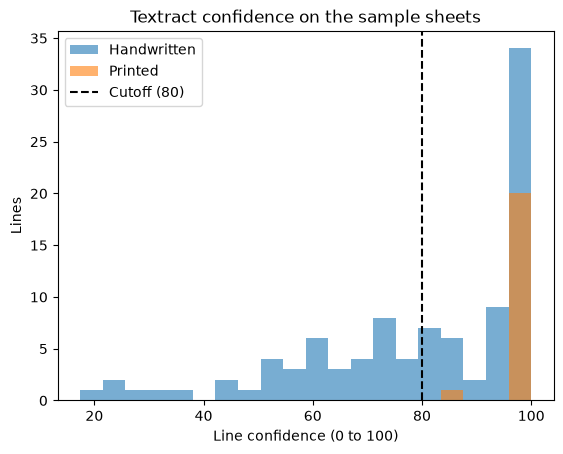

In [11]:
all_lines = pd.concat(lines.values(), ignore_index=True)
all_lines["writing"] = all_lines["handwritten"].map({True: "Handwritten", False: "Printed"})
all_lines.pivot(columns="writing", values="conf").plot.hist(bins=20, alpha=0.6)
plt.axvline(LOW_CONF, color="black", linestyle="--", label=f"Cutoff ({LOW_CONF})")
plt.xlabel("Line confidence (0 to 100)")
plt.ylabel("Lines")
plt.title("Textract confidence on the sample sheets")
plt.legend()
plt.show()

- Five of the seven hours that lost their decimal on HW-04 ("2", "6", "9 9", "2", "7") read at 51 to 81 confidence, so low confidence catches most of them.
- Two don't: "3" (92) and "4" (98.5). Confidence alone isn't enough, so hours written without a decimal point also need a check.
- One correct value is also low: "0.4" on page 1 (74), so a low score means "check this", not "wrong".
- About 4 in 10 handwritten lines fall under the cutoff, mostly narratives and client names. Misread names are handled by matching's fuzzy matching, so the confidence check matters most for hours and CMIDs.

## 8. Hard-to-read lines on the page

Lines below the confidence cutoff are boxed on each page, to see whether low confidence lines up with text that is actually hard to read.

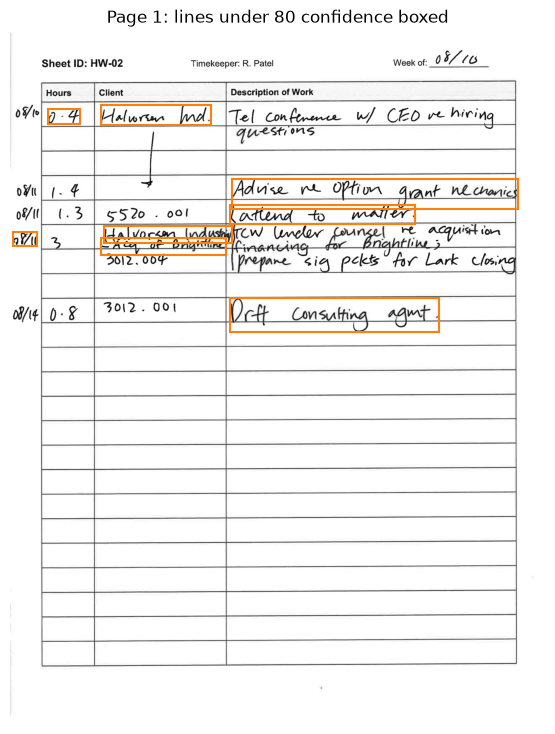

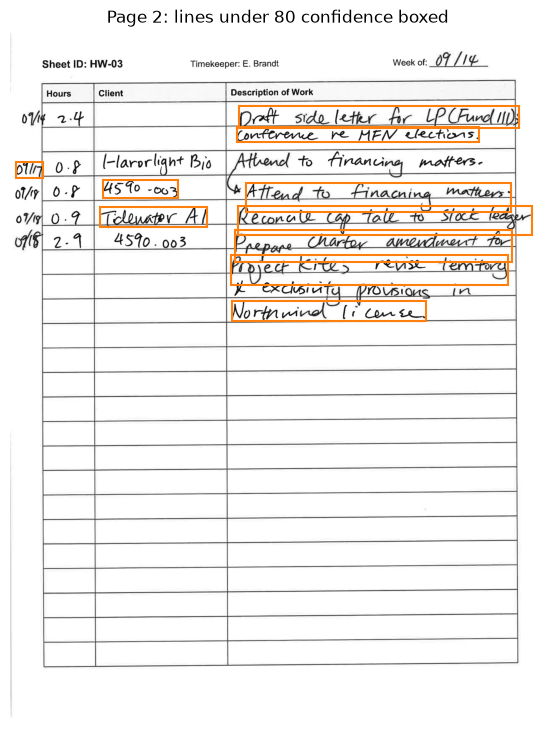

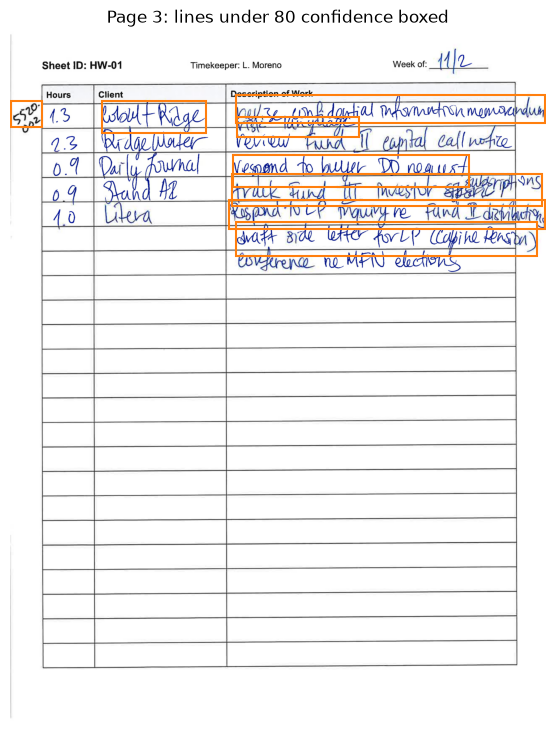

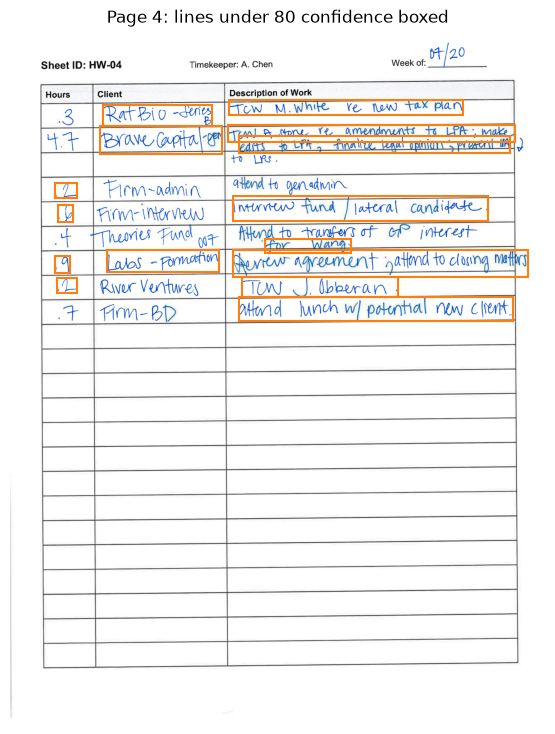

In [12]:
def show_page(image, text_lines, title):
    img = ImageOps.exif_transpose(Image.open(io.BytesIO(image)))   # phone photos are stored sideways
    w, h = img.size
    fig, ax = plt.subplots(figsize=(7, 9))
    ax.imshow(img)
    for _, ln in text_lines[text_lines["conf"] < LOW_CONF].iterrows():
        ax.add_patch(patches.Rectangle((ln["left"] * w, ln["top"] * h), ln["width"] * w, ln["height"] * h,
                                       fill=False, edgecolor="C1", linewidth=1.5))
    ax.set_title(title)
    ax.axis("off")
    plt.show()


for n, image in enumerate(page_images(SHEETS_PATH, DPI), 1):
    show_page(image, lines[n], f"Page {n}: lines under {LOW_CONF} confidence boxed")

- The boxes line up with writing that is actually hard to read: messy client names ("Brave Capital-gen"), cramped narratives, and the hours on HW-04 that are missing their decimal.
- Apart from "0.4" on page 1, every hour on pages 1 to 3 reads at 97 or above.

## 9. Loose notes

Each photo's lines in reading order, then the photo with hard-to-read lines boxed. A note with drawn columns is also shown as Textract's table, since reading line by line can mix text from different columns.

mon_fri_sample.jpg


,text,conf,handwritten
0,01...5PM,95.5,False
1,Mon.,83.9,True
2,X,93.6,True
3,09/21/26,84.9,True
4,1238.001,99.0,True
5,Attend to call with,83.4,True
6,.4,61.2,True
7,T.Smith re financial plan,60.9,True
8,Pream Al,55.9,True
9,4599.002,99.3,True


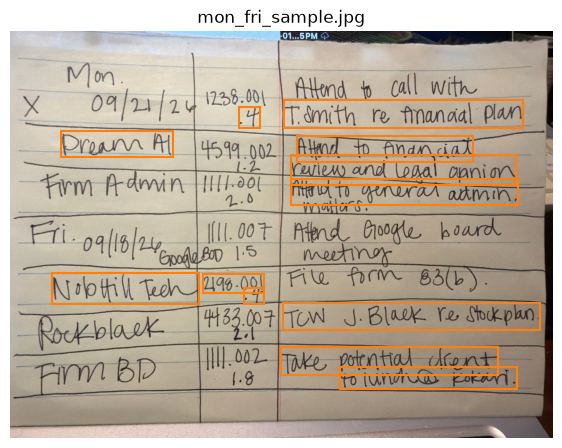

note_01.JPG


,text,conf,handwritten
0,4 Halvorsen -,74.0,True
1,call w/lender,97.8,True
2,counselve Brightline,58.9,True
3,closing,99.1,True


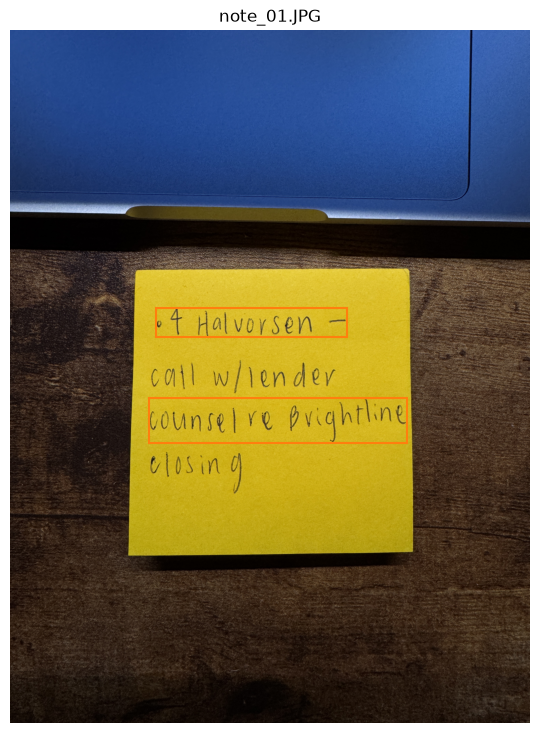

note_02.JPG


,text,conf,handwritten
0,10127,81.1,True
1,5602.003 1.6,96.3,True
2,review Quanta,87.0,True
3,disclosure schedules,93.6,True


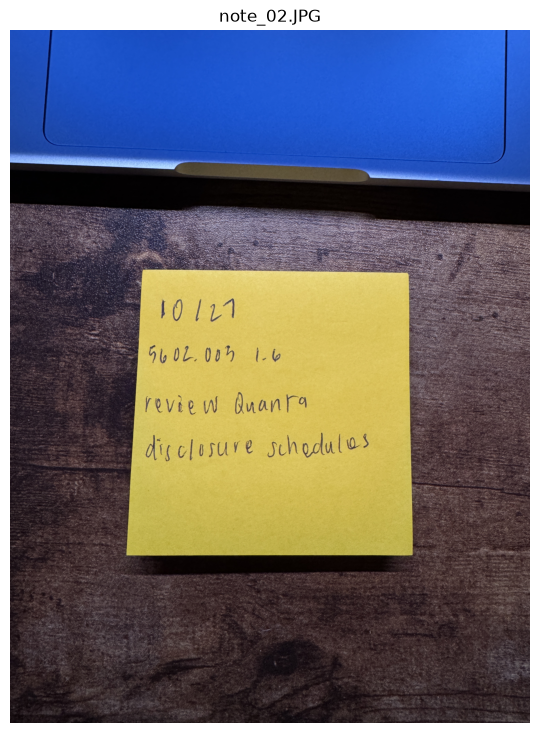

note_03.JPG


,text,conf,handwritten
0,Ironwood 2.5 diligence,96.9,True
1,calls w/ Quanta mgmt,96.0,True
2,"same - markup SPA , 8",39.1,True


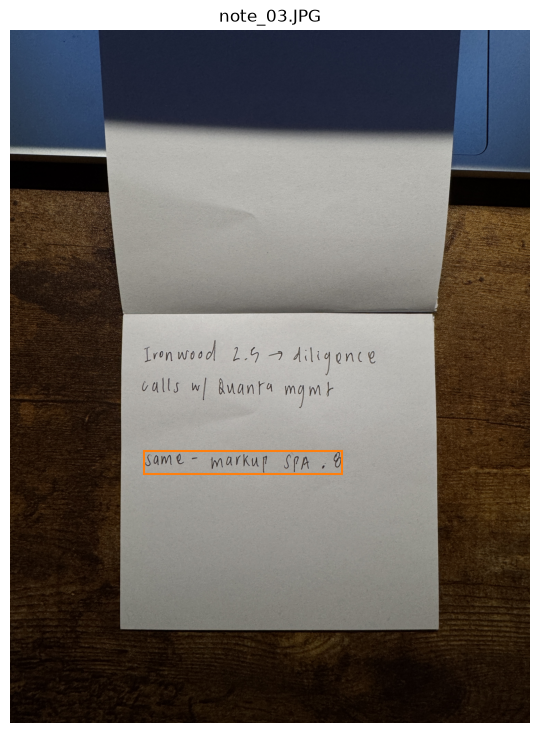

note_04.JPG


,text,conf,handwritten
0,Tidewater Analytics 1.2,99.5,True
1,draft side letter for,97.1,True
2,Series A & arm lead,23.0,True
3,Firm admin .3 3 time,87.9,True
4,entries,95.4,True


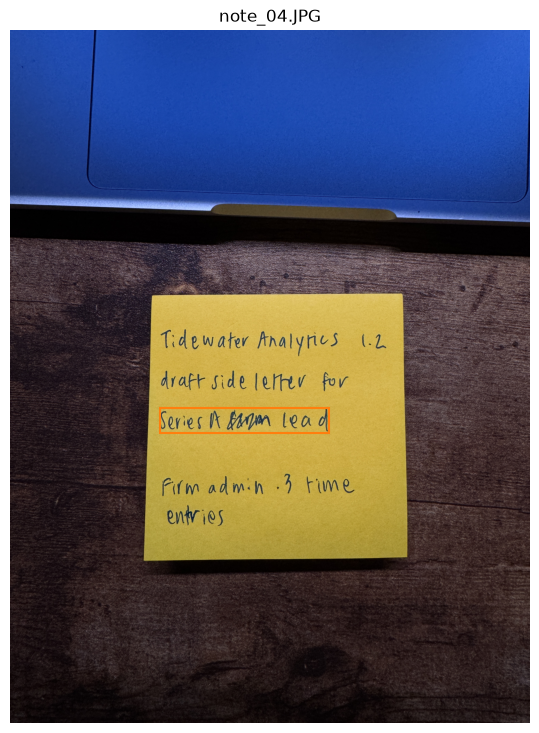

note_05.JPG


,text,conf,handwritten
0,No.,97.7,False
1,Date,99.2,False
2,Mon 10126,88.1,True
3,Orchard Lane .9,74.4,True
4,review Vendor contract,98.4,True
5,Tues 10/21,91.5,True
6,Solace Health 1.1,79.0,True
7,board minutes,64.2,True
8,KOKUYO 1005E-LEAR,20.3,False


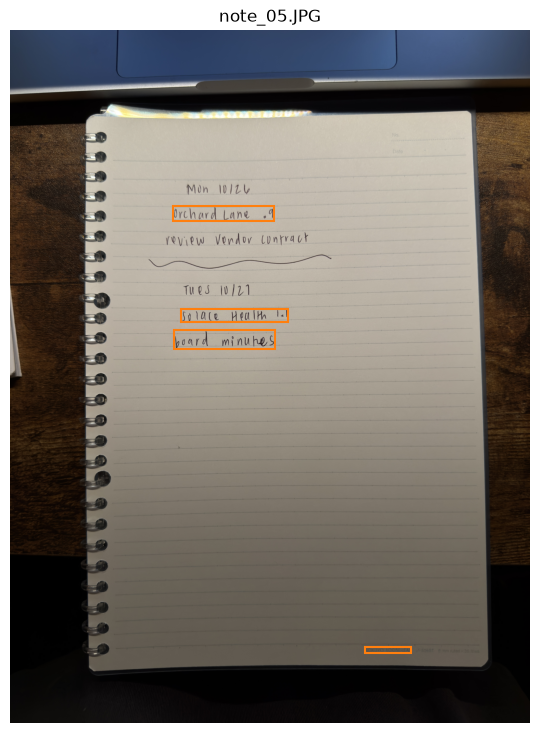

note_06.JPG


,text,conf,handwritten
0,Ridgeview 05 call re capital call,62.9,True
1,Firm BD 1.0 lunch w/ prospective,95.3,True
2,client,83.5,True


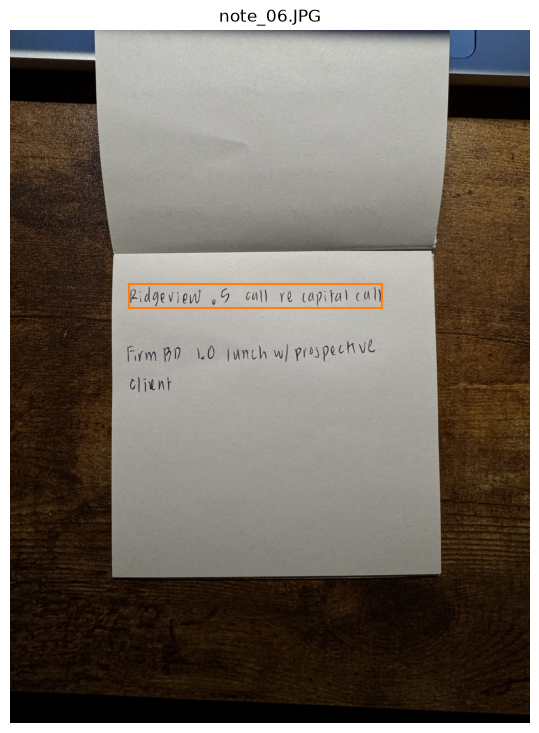

note_07.JPG


,text,conf,handwritten
0,3012.004,91.0,True
1,ravise disclosure,74.2,True
2,Wed 10/28,86.3,True
3,schedules for,99.8,True
4,1.4,99.8,True
5,Brightline,99.0,True
6,Halvorsen,99.0,True
7,2.0,99.5,True
8,TCW buyer counsel,80.3,True
9,re oscrow,52.4,True


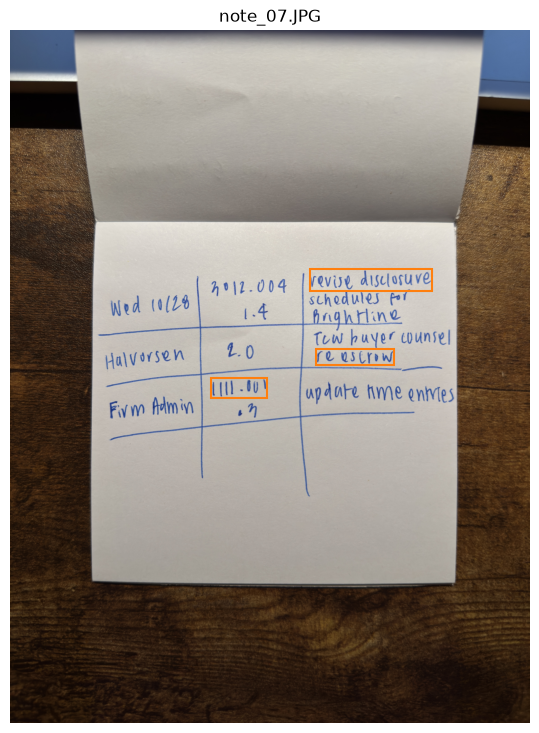

note_08.JPG


,text,conf,handwritten
0,1: 1:15 15 tronwood,49.6,True
1,$77 Prism bringdown call,17.8,True


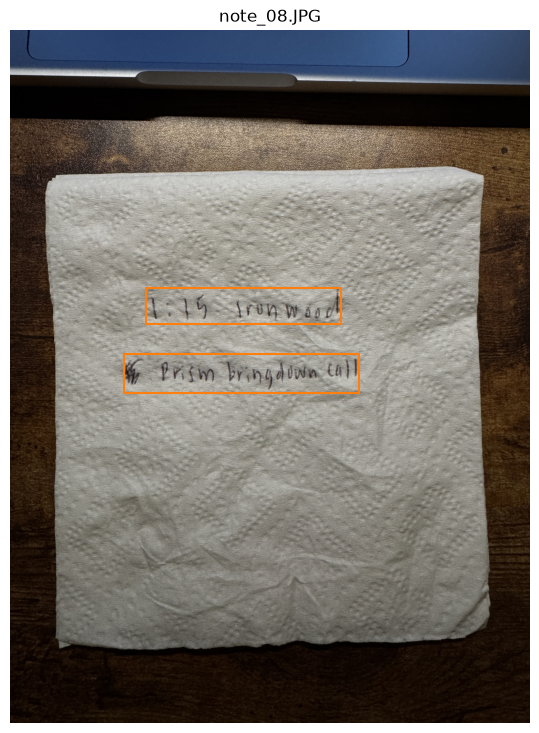

In [13]:
for photo in photos:
    note_lines = page_lines(load_pages(TEXTRACT_DIR, photo, "note")[0])
    print(photo.name)
    display(note_lines[["text", "conf", "handwritten"]].round(1))
    show_page(page_images(photo)[0], note_lines, photo.name)

In [14]:
for photo in photos:
    if photo.name in COLUMN_NOTES:
        print(f"{photo.name} read as a sheet")
        display(table_grid(page_cells(load_pages(TEXTRACT_DIR, photo, "sheet")[0])))

mon_fri_sample.jpg read as a sheet


col,1,2,3
row,,,
1,Mon. X 09/21/26,1238.001 .4,Attend to call with T.Smith re financial plan
2,Pream Al,4599.002 1.2,Attend to financial review and Legal
3,Firm Admin,1111.001 2.0,opnion Attend to general admin. matters.
4,Fri. 09/18/26 Google,1111.007 BOD 1.5,Attend Google board meeting
5,Nobttill Tech,2198.001 .4,File form 83(b).
6,Rockblack,4433.007 2.1,TCW J.Black re Stockplan.
7,Firm BD,1111.002 1.8,Take potential drent to lundh@ kokan.
8,,,


note_07.JPG read as a sheet


col,1,2,3
row,,,
1,,3012.004,ravise disclosure
2,Wed 10/28,1.4,schedules for Brightline
3,Halvorsen,2.0,TCW buyer counsel re oscrow
4,Firm Admin,1111.001 in,update time entries


- The words on phone photos read well: most lines come back nearly word for word, on sticky notes, notepads, and a napkin.
- Small marks are the weak spot. Leading decimal points get dropped or misread (".4" as "4", ".5" as "05", ".8" as ", 8", ".3" as "in"), and the slash in a date can read as a 1 ("10/27" as "10127").
- Printed text on the paper is read too (a notebook's "No." and "Date" labels, a brand name, a laptop clock), but Textract marks it as printed, so it can be skipped.
- Notes with columns drawn on them come back as tables. A line that wraps inside a cell can become its own table row.
- Leading decimals matter most, since ".4" is how hours are usually written. Some can be recovered ("05" as .5), but a dot that disappears completely can only be flagged.

## Findings

### Results
- **Header:** sheet ID, timekeeper, and week come through on every sheet, and every timekeeper maps to the right TK ID.
- **Table:** rows follow the form, but margin dates sometimes land inside the table as an extra column, and continuation lines come back as separate rows.
- **Margins:** the dates and the sideways CMID are in the saved answer, outside the table. The table-only export lost them.
- **Hours:** confidence catches 5 of the 7 hours that lost their decimal. A no-decimal-point check is needed for the other two.
- **Note photos:** words read well, but small decimal points and date slashes are often lost, which matters most for hours.

### Tradeoffs
- Saving the full answer costs a little disk space but means each page is paid for once, and the converters can be changed and rerun without calling Textract again.
- Forms mode costs more per page than tables alone, in exchange for the sheet header.

### Limitations
- Four sheets from a few writers, and a small set of note photos, so confidence cutoffs set here are a starting point.
- Textract reads text only. A drawn arrow meaning "same as above" comes back as a blank cell.

### Next steps
- Hand-check the answer keys (`data/sheets_answer_key.csv`, `data/notes_answer_key.csv`) against the scans and photos.
- Build the sheet converter on the saved answers and grade it against the answer key (notebook 01).
- Run the note photos through the free-text converter (notebook 02).